# Attention, Transformer и BERT. Word-level и subword

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "11_bert_tokenization"
OUT.mkdir(exist_ok=True, parents=True)

## Данные, baseline и вариант 11

20 Newsgroups: четыре темы, 1000 текстов. Сравниваю токенизацию и пять моделей. Word-level словарь строю по train, для WordPiece беру предобученный словарь. Код — в language_music.py.

Источник: 20 Newsgroups, четыре темы, заголовки/подписи/цитаты удалены; 600/200/200. Word vocabulary обучен только на train. BERT: prajjwal1/bert-tiny (2 слоя, hidden=128).
Word tokens: ['yeah', 'of', 'course', 'the', 'term', 'mach', 'banding', 'was', 'not', 'the', 'correct', 'one', 'it', "should've", 'been', 'color', 'quantization', 'effect', 'although', 'a']
WordPiece: ['yeah', ',', 'of', 'course', '.', '.', '.', 'the', 'term', "'", 'mach', 'band', '##ing', "'", 'was', 'not', 'the', 'correct', 'one', ',', 'it', 'should', "'", 've', 'been', "'", 'color', 'quan', '##ti', '##zation']


,tokenizer,mean_tokens_untruncated,UNK_token_fraction,mean_kept_tokens,vocab_size
0,word,200.725,0.10987,52.515,6002
1,subword,300.725,0.00000,58.110,30522


,class,precision,recall,f1-score,support
0,0,0.87273,0.96000,0.91429,50.000
1,1,0.93182,0.83673,0.88172,49.000
2,2,0.93878,0.92000,0.92929,50.000
3,3,0.84615,0.86275,0.85437,51.000
4,accuracy,0.89500,0.89500,0.89500,0.895
5,macro avg,0.89737,0.89487,0.89492,200.000
6,weighted avg,0.89694,0.89500,0.89478,200.000


,model,validation_accuracy,validation_macro_f1,trainable_parameters,seconds
0,TFIDF_LogReg,0.825,0.82522,48000,NaN
1,word_scratch,0.810,0.80949,1182212,1.83247
2,subword_scratch,0.730,0.72349,4320772,2.01960
3,BERT_frozen,0.815,0.81487,516,0.14846
4,BERT_finetuned,0.875,0.87352,4386436,1.67403


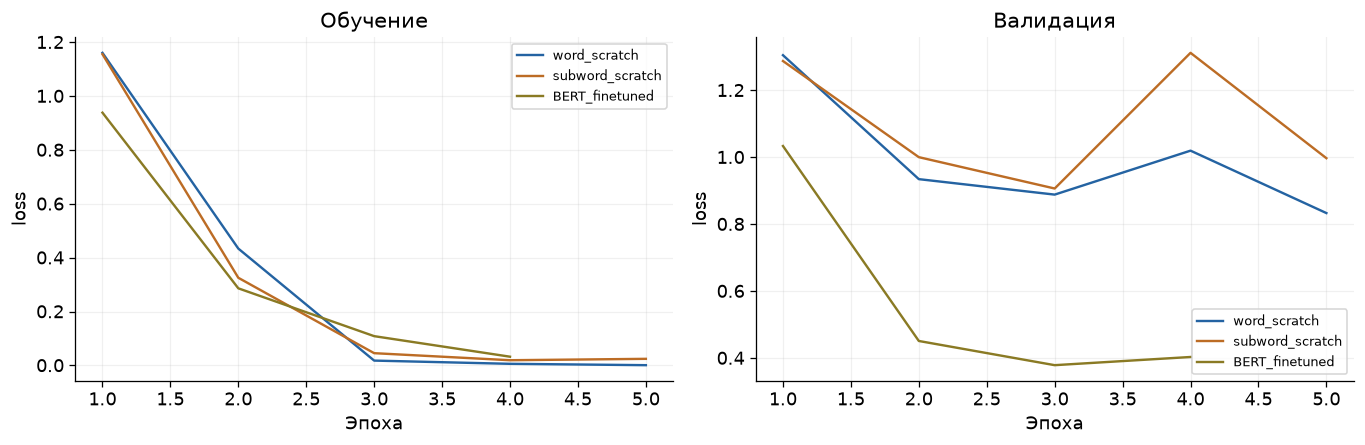

,model,test_accuracy,test_macro_f1
0,TFIDF_LogReg,0.860,0.85951
1,word_scratch,0.815,0.81681
2,subword_scratch,0.730,0.71565
3,BERT_frozen,0.780,0.78068
4,BERT_finetuned,0.895,0.89492


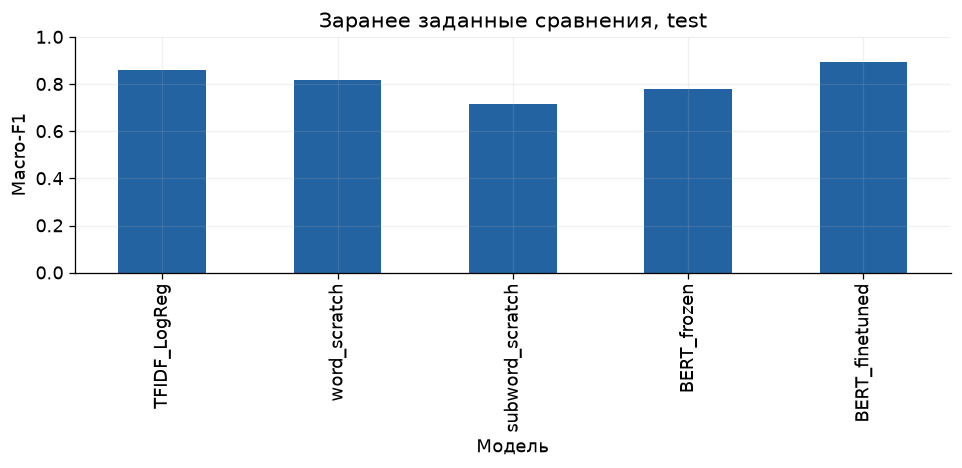

,model,row,true,predicted,correct,words,rare_words,text
5,word_scratch,277,3,1,0,318,68,Several people have enquired about the availab...
6,word_scratch,344,3,1,0,9,4,\n\n 101 Courageous Dr. \n L...
7,word_scratch,450,3,0,0,187,41,"\n\n > Why Paul, it's obvious.\n > Once ch..."
25,word_scratch,817,1,3,0,80,9,Well the European Manta and US GT have entirel...
28,word_scratch,335,3,0,0,146,45,"I have the ""osculating elements at perigee"" of..."
40,word_scratch,337,3,0,0,27,4,"\nTo compute this, and many other astronomical..."
43,word_scratch,446,1,3,0,91,13,"\nIn Des Moines, Iowa, about a year ago, some ..."
47,word_scratch,227,1,0,0,52,5,Any truth to the rumor of an AWD 3-series for ...
48,word_scratch,836,0,1,0,23,4,\nMine was beautiful for a year and a half. T...
53,word_scratch,56,2,1,0,290,33,"\nIt took three days to get to us, but I'll tr..."


,model,subset,n,accuracy
0,word_scratch,short,108,0.78704
1,word_scratch,long,92,0.84783
2,word_scratch,rare_words_ge10,102,0.85294
3,subword_scratch,short,108,0.70370
4,subword_scratch,long,92,0.76087
5,subword_scratch,rare_words_ge10,102,0.75490
6,BERT_finetuned,short,108,0.86111
7,BERT_finetuned,long,92,0.93478
8,BERT_finetuned,rare_words_ge10,102,0.95098


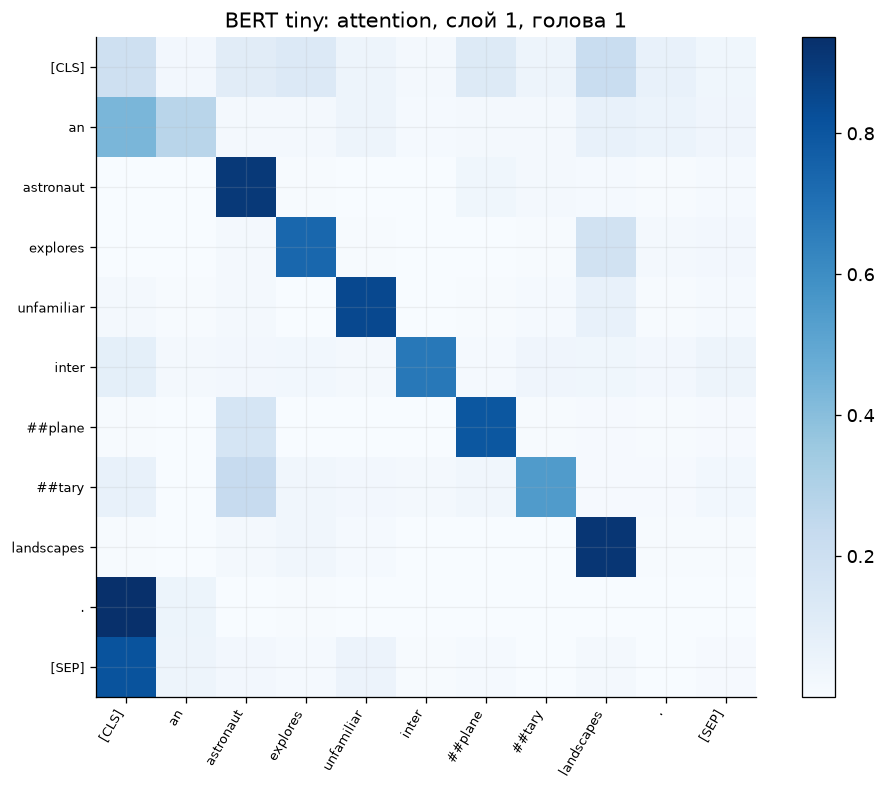

Self-attention weights:
 tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]]) 
context:
 tensor([[0.8022, 0.5989],
        [0.5989, 0.8022],
        [0.7517, 0.7517]])


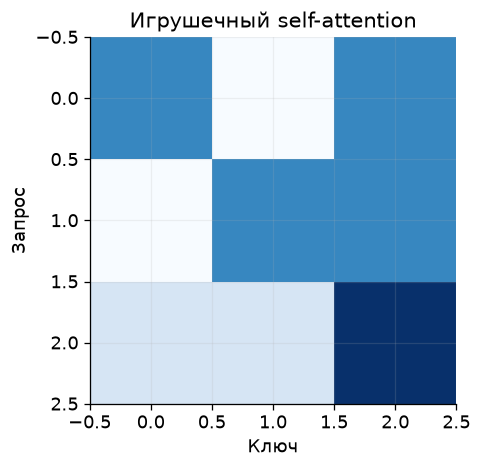

Word-level даёт UNK для новых слов. WordPiece разбивает слова на части и обычно удлиняет последовательность. Для сравнения токенизации использую word_scratch и subword_scratch с одинаковыми размерами encoder. Размеры embedding-таблиц различаются. У предобученного BERT также меняются исходные веса. Attention-карта показывает веса одной головы и сама по себе не объясняет причину ответа.

Позиционные embeddings задают порядок, residual-связи помогают передавать градиент, LayerNorm нормализует признаки токена. При mean pooling исключаю PAD через attention_mask. Все пять моделей заданы до оценки test; бюджет обучения небольшой.

In [2]:
from language_music import bert_tokenization

bert_tokenization(OUT)

## Вывод по гипотезе

Проверяю долю UNK, длину последовательностей и качество классификации при word-level и subword токенизации.

In [3]:
note(
    "Результаты UNK, длины последовательностей и ошибок на редких словах сохранены отдельно от итогового качества моделей. Уменьшение UNK само по себе не гарантирует роста macro-F1. При фиксированном max_length=64 более длинная subword-последовательность сильнее обрезается. Замороженный BERT и fine-tuning сравниваются с TF-IDF baseline; это отдельное сравнение роли предобучения."
)

Результаты UNK, длины последовательностей и ошибок на редких словах сохранены отдельно от итогового качества моделей. Уменьшение UNK само по себе не гарантирует роста macro-F1. При фиксированном max_length=64 более длинная subword-последовательность сильнее обрезается. Замороженный BERT и fine-tuning сравниваются с TF-IDF baseline; это отдельное сравнение роли предобучения.

## Ответы на контрольные вопросы

1. Q — запросы, K — ключи для сходства, V — значения, усредняемые с вычисленными весами внимания.

2. Масштабирование на sqrt(d_k) сдерживает рост разброса скалярных произведений и насыщение softmax.

3. Без позиционной информации self-attention не различает перестановки как упорядоченную последовательность.

4. BERT — двунаправленный encoder с предобучением по маскированию; causal decoder ограничивает внимание прошлым и обучается продолжать текст.

5. Веса attention описывают одну операцию смешивания; они не учитывают весь путь residual, MLP и последующие слои и не устанавливают причинную важность.